# Khám phá Dữ liệu (EDA) - Palmer Penguins
**Mục tiêu:** Phân tích sự phân bố của các đặc trưng hình thái học trên tập **Train** để làm cơ sở cho quyết định tiền xử lý dữ liệu. Tuyệt đối không chạm vào tập Validation và Test trong quá trình này để tránh rò rỉ dữ liệu (Data Leakage).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cài đặt phong cách vẽ biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Tải và Gộp tập Train
Tải dữ liệu `X_train.csv` và `y_train.csv` (đã được chia tại `src/data.py`) và gộp lại thành một DataFrame tạm thời để vẽ biểu đồ.

In [2]:
X_train = pd.read_csv('X_train.csv')
y_train = pd.read_csv('y_train.csv').squeeze()

# Gộp dữ liệu để EDA
df_train = X_train.copy()
df_train['species'] = y_train

print(df_train.info())
display(df_train.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 239 entries, 0 to 238
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   island             239 non-null    object 
 1   bill_length_mm     239 non-null    float64
 2   bill_depth_mm      239 non-null    float64
 3   flipper_length_mm  239 non-null    float64
 4   body_mass_g        239 non-null    float64
 5   sex                233 non-null    object 
 6   species            239 non-null    object 
dtypes: float64(4), object(3)
memory usage: 13.2+ KB
None


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,239.000000,239.000000,239.000000,239.000000
mean,44.095397,17.137238,201.025105,4223.326360
std,5.582515,2.053915,13.909952,789.340967
min,33.100000,13.100000,172.000000,2700.000000
25%,39.550000,15.300000,190.000000,3575.000000
50%,44.100000,17.500000,197.000000,4050.000000
75%,49.000000,18.700000,213.000000,4762.500000
max,59.600000,21.500000,231.000000,6300.000000


## 2. Phân bố các loài chim (Target)
Kiểm tra xem dữ liệu có bị mất cân bằng quá mức hay không.

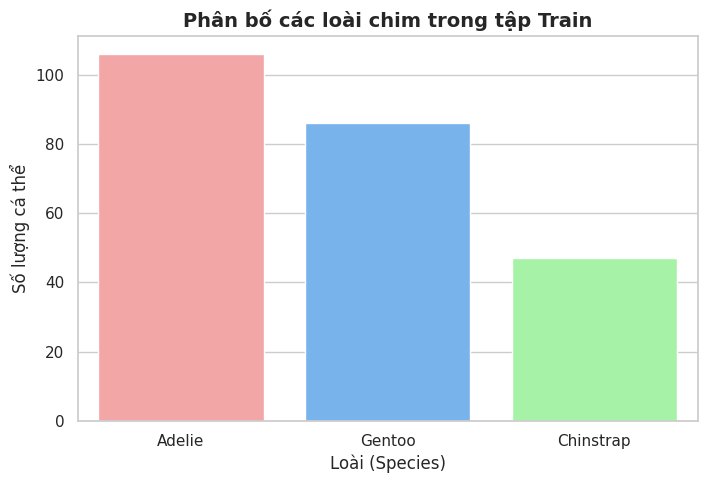

In [7]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_train,
    x='species',
    hue='species',
    palette=['#FF9999', '#66B3FF', '#99FF99'],
    legend=False
)

plt.title('Phân bố các loài chim trong tập Train',
          fontsize=14, fontweight='bold')
plt.ylabel('Số lượng cá thể')
plt.xlabel('Loài (Species)')
plt.show()

## 3. Trực quan hóa 4 đặc trưng hình thái học
Sử dụng Pairplot để xem xét sự phân tách không gian giữa 3 loài dựa trên 4 biến số (Dài mỏ, Dày mỏ, Dài vây, Khối lượng). Đây là cơ sở toán học để K-NN hoạt động.

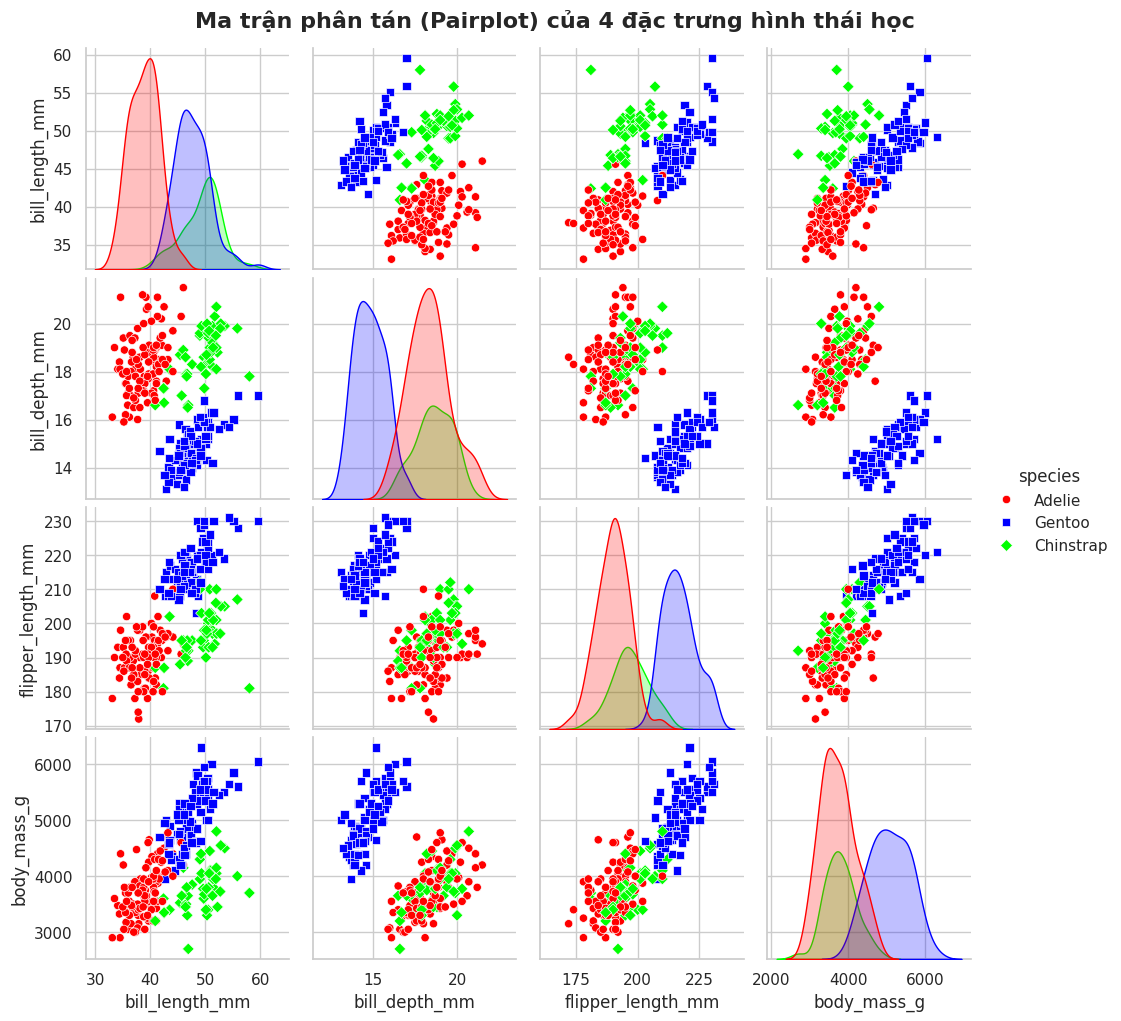

In [8]:
# Chọn 4 đặc trưng số
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "species"]

sns.pairplot(df_train[num_cols], hue="species", palette=['#FF0000', '#0000FF', '#00FF00'], markers=["o", "s", "D"])
plt.suptitle('Ma trận phân tán (Pairplot) của 4 đặc trưng hình thái học', y=1.02, fontsize=16, fontweight='bold')
plt.show()

# Nhận xét:
# - Loài Gentoo tách biệt rất rõ rệt ở đặc trưng flipper_length (vây dài) và body_mass (nặng).
# - Adelie và Chinstrap có sự giao thoa lớn ở flipper_length và body_mass, nhưng phân tách tốt ở bill_length (mỏ Chinstrap dài hơn hẳn Adelie).
# - Vì các dải giá trị rất khác nhau (body_mass lên tới 6000g, bill_depth chỉ 20mm), BẮT BUỘC phải chuẩn hóa (StandardScaler) trước khi chạy K-NN.